Train: (60000, 784) (60000,)
Test : (10000, 784) (10000,)
Форма изображения: (28, 28)


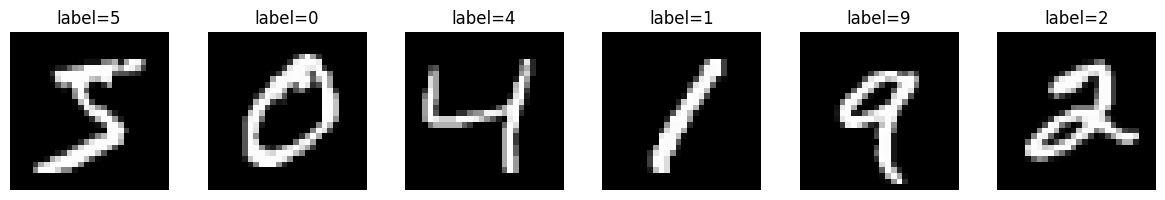

Epoch  1/20 | train error = 0.0665 | 9.1s
Epoch  2/20 | train error = 0.0433 | 9.0s
Epoch  3/20 | train error = 0.0327 | 6.6s
Epoch  4/20 | train error = 0.0250 | 6.2s
Epoch  5/20 | train error = 0.0265 | 6.3s
Epoch  6/20 | train error = 0.0186 | 7.2s
Epoch  7/20 | train error = 0.0162 | 5.8s
Epoch  8/20 | train error = 0.0138 | 7.1s
Epoch  9/20 | train error = 0.0116 | 8.1s
Epoch 10/20 | train error = 0.0096 | 6.3s
Epoch 11/20 | train error = 0.0113 | 6.2s
Epoch 12/20 | train error = 0.0081 | 6.2s
Epoch 13/20 | train error = 0.0064 | 7.0s
Epoch 14/20 | train error = 0.0074 | 8.3s
Epoch 15/20 | train error = 0.0048 | 9.2s
Epoch 16/20 | train error = 0.0040 | 7.4s
Epoch 17/20 | train error = 0.0038 | 7.4s
Epoch 18/20 | train error = 0.0037 | 6.6s
Epoch 19/20 | train error = 0.0025 | 7.0s
Epoch 20/20 | train error = 0.0027 | 6.6s

Test error = 0.0190, Test accuracy = 0.9810


In [8]:
import numpy as np
import matplotlib.pyplot as plt
import time

data = np.load('mnist.npz')

x_train, y_train, x_test, y_test = (data['x_train'], data['y_train'], data['x_test'], data['y_test'])

x_train = x_train.reshape(-1, 784).astype(np.float32) / 255.0
x_test = x_test.reshape(-1, 784).astype(np.float32) / 255.0

def one_hot(y, k=10):
    out = np.zeros((y.size, k), dtype=np.float32)
    out[np.arange(y.size), y] = 1.0
    return out

y_train_oh = one_hot(y_train)
y_test_oh = one_hot(y_test)

print("Train:", x_train.shape, y_train.shape)
print("Test :", x_test.shape,  y_test.shape)
print("Форма изображения:", (28, 28))

fig, axes = plt.subplots(1, 6, figsize=(12, 2))
for i, ax in enumerate(axes):
    ax.imshow(x_train[i].reshape(28, 28), cmap='gray')
    ax.set_title(f"label={y_train[i]}")
    ax.axis('off')
plt.tight_layout()
plt.show()

def init_params(n_in=784, n_hidden=300, n_out=10):
    rng = np.random.default_rng(42)
    W1 = rng.normal(0, np.sqrt(2.0 / n_in), (n_hidden, n_in )).astype(np.float32)
    b1 = np.zeros(n_hidden, dtype=np.float32)
    W2 = rng.normal(0, np.sqrt(2.0 / n_hidden), (n_out,  n_hidden)).astype(np.float32)
    b2 = np.zeros(n_out, dtype=np.float32)

    return W1, b1, W2, b2

def forward(X, W1, b1, W2, b2):
    Z1 = X @ W1.T + b1 
    H  = np.maximum(Z1, 0.0)
    Z2 = H @ W2.T + b2
    Z2 = Z2 - Z2.max(axis=1, keepdims=True)
    expZ = np.exp(Z2)
    Yhat = expZ / expZ.sum(axis=1, keepdims=True)

    return Z1, H, Yhat

def backward(X, Y_oh, Z1, H, Yhat, W2):
    B = X.shape[0]

    dZ2 = (Yhat - Y_oh) / B
    dW2 = dZ2.T @ H
    db2 = dZ2.sum(axis=0)

    dH  = dZ2 @ W2
    dZ1 = dH * (Z1 > 0)
    dW1 = dZ1.T @ X
    db1 = dZ1.sum(axis=0)

    return dW1, db1, dW2, db2

def train(X, Y, Y_oh, epochs=20, batch_size=64, lr=0.1,
          n_hidden=300, X_test=None, y_test=None):
    W1, b1, W2, b2 = init_params(n_hidden=n_hidden)
    N = X.shape[0]
    history = []

    for epoch in range(epochs):
        t0 = time.time()
        idx = np.random.permutation(N)
        X_sh, Y_oh_sh = X[idx], Y_oh[idx]

        for start in range(0, N, batch_size):
            end = start + batch_size
            xb = X_sh[start:end]
            yb = Y_oh_sh[start:end]

            Z1, H, Yhat = forward(xb, W1, b1, W2, b2)
            dW1, db1, dW2, db2 = backward(xb, yb, Z1, H, Yhat, W2)

            W1 -= lr * dW1;  b1 -= lr * db1
            W2 -= lr * dW2;  b2 -= lr * db2

        _, _, Yhat_tr = forward(X, W1, b1, W2, b2)
    
        y_pred = Yhat_tr.argmax(axis=1)
        y_true = Y.ravel() if Y.ndim > 1 else Y
        train_err = 1.0 - np.mean(y_pred == y_true)

        dt = time.time() - t0
        history.append((epoch + 1, train_err, dt))
        print(f"Epoch {epoch+1:2d}/{epochs} | train error = {train_err:.4f} | {dt:.1f}s")

    _, _, Yhat_te = forward(X_test, W1, b1, W2, b2)
    test_acc = np.mean(Yhat_te.argmax(1) == y_test)
    test_err = 1.0 - test_acc
    print(f"\nTest error = {test_err:.4f}, Test accuracy = {test_acc:.4f}")

train(
    x_train, y_train, y_train_oh,
    epochs=20, batch_size=64, lr=0.1, n_hidden=300,
    X_test=x_test, y_test=y_test)